In [ ]:
!pip install split-folders

Copying files: 202 files [01:39,  2.03 files/s]


In [ ]:
import splitfolders
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

INPUT_DIR = '/content/drive/MyDrive/Skripsi/Dataset'

OUTPUT_DIR = '/content/drive/MyDrive/Skripsi/Data split 1'


splitfolders.ratio(INPUT_DIR, output=OUTPUT_DIR, seed=42, ratio=(.8, .2), group_prefix=None)

print("Proses pengacakan folder selesai!")


Copying files: 0 files [00:00, ? files/s]
Copying files: 2 files [00:00, 17.52 files/s]
Copying files: 4 files [00:00,  7.66 files/s]
Copying files: 9 files [00:00, 17.55 files/s]
Copying files: 12 files [00:00, 16.78 files/s]
Copying files: 15 files [00:00, 18.84 files/s]
Copying files: 18 files [00:01, 18.84 files/s]
Copying files: 22 files [00:01, 20.60 files/s]
Copying files: 26 files [00:01, 24.68 files/s]
Copying files: 29 files [00:01, 21.91 files/s]
Copying files: 32 files [00:01, 17.93 files/s]
Copying files: 35 files [00:01, 17.54 files/s]
Copying files: 39 files [00:02, 20.65 files/s]
Copying files: 42 files [00:02, 15.41 files/s]
Copying files: 44 files [00:02, 12.47 files/s]
Copying files: 46 files [00:02, 13.46 files/s]
Copying files: 48 files [00:02, 13.85 files/s]
Copying files: 50 files [00:03, 12.87 files/s]
Copying files: 52 files [00:03, 12.76 files/s]
Copying files: 54 files [00:03, 10.44 files/s]
Copying files: 57 files [00:03, 12.23 files/s]
Copying files: 59 fi

Proses pengacakan folder selesai!


In [ ]:



TRAIN_DIR = '/content/drive/MyDrive/Skripsi/Data split 1/train'
VAL_DIR = '/content/drive/MyDrive/Skripsi/Data split 1/val'


train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

In [ ]:


val_datagen = ImageDataGenerator(rescale=1./255)


In [ ]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(150, 150),
    batch_size=16,
    class_mode='categorical'
)

validation_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(150, 150),
    batch_size=16,
    class_mode='categorical',
    shuffle=False
)

Found 480 images belonging to 6 classes.
Found 120 images belonging to 6 classes.


In [ ]:
base_model = MobileNetV2(input_shape=(150, 150, 3),
                         include_top=False,
                         weights='imagenet')
base_model.trainable = False

/tmp/ipykernel_1029/2761310001.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(150, 150, 3),


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Tambahkan layer khusus untuk dataset kita
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# Output Layer untuk 6 Kelas
predictions = Dense(6, activation='softmax')(x)

# Gabungkan model
model_mobilenet = Model(inputs=base_model.input, outputs=predictions)

# Compile
model_mobilenet.compile(optimizer='adam',
                        loss='categorical_crossentropy',
                        metrics=['accuracy'])

model_mobilenet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 75, 75,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 75, 75,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 75, 75,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 75, 75,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 75, 75,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 75, 75,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 77, 77,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 38, 38,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 38, 38,    │      2,304 │ block_1_depthwis

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
print("Mulai melatih model MobileNet...")

history_mobilenet = model_mobilenet.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator
)

Mulai melatih model MobileNet...
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.3500 - loss: 1.8187 - val_accuracy: 0.6917 - val_loss: 0.9337
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.5875 - loss: 1.0491 - val_accuracy: 0.6833 - val_loss: 0.8383
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.7208 - loss: 0.7156 - val_accuracy: 0.7083 - val_loss: 0.6970
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.7479 - loss: 0.6326 - val_accuracy: 0.7750 - val_loss: 0.6441
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.8396 - loss: 0.4916 - val_accuracy: 0.7917 - val_loss: 0.6109
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.8271 - loss: 0.4440 - val_accuracy: 0.7917 - val_loss: 0.6260
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.8333 - loss: 0.4823 - val_accuracy: 0.7500 - val_loss: 0.6835
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8562 - loss: 0.3896 -

Sedang memproses prediksi model MobileNetV2...
8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step

================ HASIL EVALUASI MODEL MOBILENETV2 ================
              precision    recall  f1-score   support

Adallyn bag        0.73      0.80      0.76        20
  Bucket Bag       0.86      0.95      0.90        20
   Calla bag       0.86      0.90      0.88        20
  Iveyt shoe       0.92      0.60      0.73        20
  Midori Bag       0.89      0.85      0.87        20
 lando shoe        0.78      0.90      0.84        20

    accuracy                           0.83       120
   macro avg       0.84      0.83      0.83       120
weighted avg       0.84      0.83      0.83       120



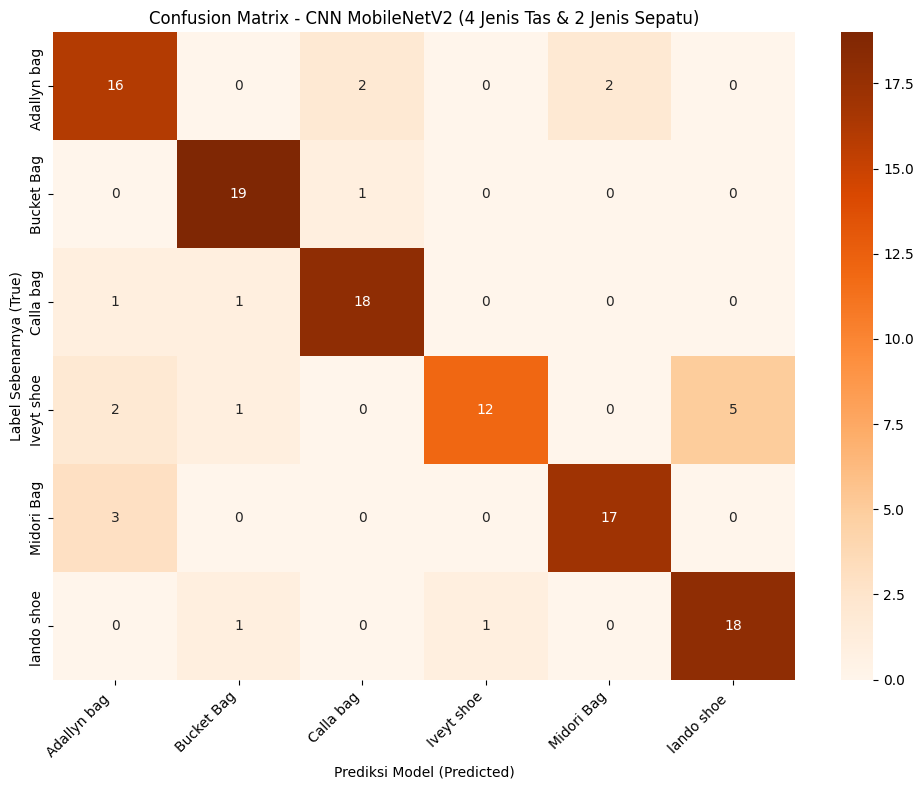

In [ ]:
print("Sedang memproses prediksi model MobileNetV2...")
Y_pred = model_mobilenet.predict(validation_generator)
y_pred = np.argmax(Y_pred, axis=1)

y_true = validation_generator.classes

class_names = list(validation_generator.class_indices.keys())

print("\n================ HASIL EVALUASI MODEL MOBILENETV2 ================")
print(classification_report(y_true, y_pred, target_names=class_names))
print("==================================================================")

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title('Confusion Matrix - CNN MobileNetV2 (4 Jenis Tas & 2 Jenis Sepatu)')
plt.ylabel('Label Sebenarnya (True)')
plt.xlabel('Prediksi Model (Predicted)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

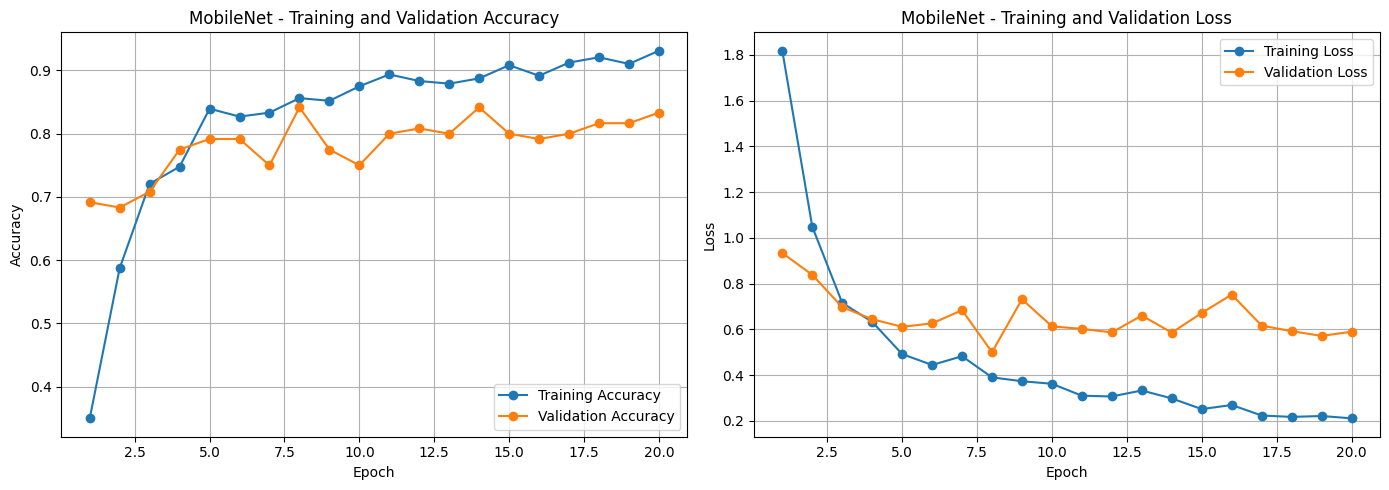

In [ ]:
acc = history_mobilenet.history['accuracy']
val_acc = history_mobilenet.history['val_accuracy']
loss = history_mobilenet.history['loss']
val_loss = history_mobilenet.history['val_loss']


epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.legend(loc='lower right')
plt.title('MobileNet - Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.legend(loc='upper right')
plt.title('MobileNet - Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()